In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Amazon Bestseller Book Analysis

## 1. Introduction

This project analyzes Amazon's top-selling products to identify
patterns and trends related to book ratings, reviews, prices,
authors, and categories.

## 2. Dataset Overview

The dataset contains 4,846 rows and 10 columns, one row per Amazon product listing.

**Source:** _add the link and credit for where `amazon_books.csv` was downloaded._

The file has no collection date, but many titles are 2024 calendars and almanacs, so it looks like a single snapshot from around 2023 to 2024. Prices are assumed to be in US dollars and `Rank` is assumed to be Amazon's best-seller rank (1 = best seller); neither is documented in the file.

In [2]:
df = pd.read_csv("data/amazon_books.csv")
df.head()

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages
0,"Fourth Wing (The Empyrean, 1)",1,4.8,135916,18.69,Fantasy,Entangled: Red Tower Books,Macmillan,Rebecca Yarros,528.0
1,Atomic Habits: An Easy & Proven Way to Build G...,2,4.8,120356,12.50,Personal Transformation,Avery,Avery,James Clear,320.0
2,"Iron Flame (The Empyrean, 2)",3,4.7,79851,14.78,Epic,Entangled: Red Tower Books,Kiligry,Rebecca Yarros,640.0
3,"Dinner Tonight: 100 Simple, Healthy Recipes fo...",4,4.1,6,26.00,Natural Foods,William Morrow Cookbooks,NaN,Alex Snodgrass,256.0
4,Oath and Honor: A Memoir and a Warning,5,4.8,3536,21.49,Political,"Little, Brown and Company",NaN,Liz Cheney,384.0


In [3]:
df.describe()

,Rank,Reviews,Review Count,Price,Number of Pages
count,4846.000000,4846.000000,4846.000000,4846.000000,4775.000000
mean,2533.388774,4.662299,12735.633306,13.098601,347.739686
std,1500.594167,0.225194,28780.356812,10.248512,415.874433
min,1.000000,1.000000,1.000000,0.150000,1.000000
25%,1242.750000,4.600000,943.500000,7.412500,128.000000
50%,2501.500000,4.700000,4010.000000,11.100000,272.000000
75%,3768.750000,4.800000,12033.000000,15.667500,408.000000
max,15176.000000,5.000000,621499.000000,199.990000,5280.000000


In [4]:
df.shape

(4846, 10)

In [5]:
df.columns

Index(['Title', 'Rank', 'Reviews', 'Review Count', 'Price', 'Genre',
       'Manufacturer', 'Brand', 'Author', 'Number of Pages'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            4846 non-null   str    
 1   Rank             4846 non-null   int64  
 2   Reviews          4846 non-null   float64
 3   Review Count     4846 non-null   int64  
 4   Price            4846 non-null   float64
 5   Genre            4846 non-null   str    
 6   Manufacturer     4846 non-null   str    
 7   Brand            3144 non-null   str    
 8   Author           4846 non-null   str    
 9   Number of Pages  4775 non-null   float64
dtypes: float64(3), int64(2), str(5)
memory usage: 378.7 KB


In [7]:
df.isnull().sum()

Title                 0
Rank                  0
Reviews               0
Review Count          0
Price                 0
Genre                 0
Manufacturer          0
Brand              1702
Author                0
Number of Pages      71
dtype: int64

In [8]:
df[['Reviews', 'Review Count']].head(10)

,Reviews,Review Count
0,4.8,135916
1,4.8,120356
2,4.7,79851
3,4.1,6
4,4.8,3536
5,4.5,15178
6,4.4,61258
7,4.5,8072
8,5.0,1
9,5.0,1


## 3. Initial Data Checks

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Genre"].nunique()

907

In [11]:
df["Genre"].value_counts()

Genre
Fantasy                          176
Classics                         105
Genre Fiction                    101
Motivational                      99
Animals                           95
                                ... 
Fitness                            1
International Mystery & Crime      1
Scuba                              1
Interactive Adventures             1
Trading Card Games                 1
Name: count, Length: 907, dtype: int64

In [12]:
df[df["Brand"].isnull()].head()

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages
3,"Dinner Tonight: 100 Simple, Healthy Recipes fo...",4,4.1,6,26.00,Natural Foods,William Morrow Cookbooks,NaN,Alex Snodgrass,256.0
4,Oath and Honor: A Memoir and a Warning,5,4.8,3536,21.49,Political,"Little, Brown and Company",NaN,Liz Cheney,384.0
5,The Heaven & Earth Grocery Store: A Novel,6,4.5,15178,16.99,Jewish,Riverhead Books,NaN,James McBride,400.0
6,Icebreaker: A Novel (The Maple Hills Series),7,4.4,61258,10.44,Contemporary,Atria,NaN,Hannah Grace,448.0
8,Winter Turning: A Graphic Novel (Wings of Fire...,9,5.0,1,10.39,Animals,Graphix,NaN,Tui T. Sutherland,224.0


In [13]:
df[df["Number of Pages"].isnull()].head()

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages
52,Harry Potter Paperback Box Set (Books 1-7),55,4.9,103150,29.45,School,Scholastic Inc.,Arthur A. Levine Books,Rowling J,NaN
231,Flash Cards: Sight Words,236,4.8,27194,2.88,Children's Books,Scholastic Teaching Resources (Teaching Strate...,Scholastic,Resources Scholastic,NaN
324,The 2024 Old Farmer’s Almanac Gardening Calendar,336,4.7,214,5.36,Gardening & Landscape Design,Old Farmer's Almanac,NaN,Almanac Old,NaN
368,Junie B. Jones's First Boxed Set Ever! (Books ...,383,4.8,18846,6.45,New Baby,Random House Books for Young Readers,Random House Books for Young Readers,Barbara Park,NaN
406,Sierra Club Engagement Calendar 2024,423,4.9,570,17.69,Calendars,Sierra Club,KAVNLON,Club Sierra,NaN


In [14]:
df[df['Brand'].isnull()][['Title', 'Author', 'Genre', 'Brand']].head(10)

,Title,Author,Genre,Brand
3,"Dinner Tonight: 100 Simple, Healthy Recipes fo...",Alex Snodgrass,Natural Foods,NaN
4,Oath and Honor: A Memoir and a Warning,Liz Cheney,Political,NaN
5,The Heaven & Earth Grocery Store: A Novel,James McBride,Jewish,NaN
6,Icebreaker: A Novel (The Maple Hills Series),Hannah Grace,Contemporary,NaN
8,Winter Turning: A Graphic Novel (Wings of Fire...,Tui T. Sutherland,Animals,NaN
9,"Ruthless Vows (Letters of Enchantment, 2)",Rebecca Ross,Romance,NaN
14,Lessons in Chemistry: A Novel,Bonnie Garmus,Cooking,NaN
15,"Friends, Lovers, and the Big Terrible Thing: A...",Matthew Perry,Performing Arts,NaN
20,The Housemaid,Freida McFadden,Psychological,NaN
22,Haunting Adeline (Cat and Mouse Duet),H. D. Carlton,Occult,NaN


In [15]:
df[df['Number of Pages'].isnull()][['Title', 'Author', 'Genre', 'Number of Pages']].head(10)

,Title,Author,Genre,Number of Pages
52,Harry Potter Paperback Box Set (Books 1-7),Rowling J,School,NaN
231,Flash Cards: Sight Words,Resources Scholastic,Children's Books,NaN
324,The 2024 Old Farmer’s Almanac Gardening Calendar,Almanac Old,Gardening & Landscape Design,NaN
368,Junie B. Jones's First Boxed Set Ever! (Books ...,Barbara Park,New Baby,NaN
406,Sierra Club Engagement Calendar 2024,Club Sierra,Calendars,NaN
410,Sierra Club Wilderness Calendar 2024,Club Sierra,Nature,NaN
514,The Adventure Challenge Couples Edition - 50 S...,Challenge The,Family Relationships,NaN
649,Dungeons & Dragons Core Rulebooks Gift Set (Sp...,Dragons Dungeons,Genre Fiction,NaN
691,Frank Herbert's Dune Saga 3-Book Boxed Set: Du...,Frank Herbert,Classics,NaN
791,"Tile Lock Scrabble,2 to 4 players",Winning Moves Games,Scrabble,NaN


In [16]:
df['Rank'].nunique()

4027

In [17]:
df['Rank'].value_counts().head(10)

Rank
3054    4
1353    3
1486    3
1577    3
2251    3
2702    3
2930    3
3211    3
3396    3
3450    3
Name: count, dtype: int64

## 4. Data Cleaning

### 4.1 Checking for duplicate records

`df.duplicated()` (section 3) found no *identical* rows. But Amazon lists every edition of a book as a separate
product, and the review count is shared between editions, so the same book can appear several times:

In [18]:
df[df["Title"].str.startswith("Where the Crawdads Sing")][["Title", "Rank", "Review Count", "Price", "Number of Pages"]]

,Title,Rank,Review Count,Price,Number of Pages
436,Where the Crawdads Sing: Reese's Book Club (A ...,455,621499,4.99,400.0
2665,Where the Crawdads Sing: Reese's Book Club (A ...,2767,621499,5.19,384.0


Same book, same 621,499 reviews, two rows. The `Author` column has a related problem: the same person is
spelled in several ways (`Goggins David` / `David Goggins`, `Rowling J` / `J. K. Rowling`).

In [19]:
df[df["Author"].str.contains("Goggins")][["Title", "Author", "Rank"]]

,Title,Author,Rank
88,Can't Hurt Me: Master Your Mind and Defy the Odds,David Goggins,92
634,Never Finished: Unshackle Your Mind and Win th...,David Goggins,656
1235,Can't Hurt Me: Master Your Mind and Defy the Odds,Goggins David,1272
1466,Never Finished: Unshackle Your Mind and Win th...,Goggins David,1511
2059,Can't Hurt Me: Master Your Mind and Defy the O...,Goggins David,2116
4700,No me puedes lastimar: Domina tu mente y desaf...,David Goggins,5029


In [20]:
df[df["Author"].str.contains("Rowling")]["Author"].value_counts()

Author
J. K. Rowling    15
Rowling J         4
J.K. Rowling      3
J K Rowling       2
Name: count, dtype: int64

These are fixed in sections 4.4 and 4.5 below.

### 4.2 Handling missing values

In [21]:
df_clean = df.copy()

In [22]:
df_clean['Brand'] = df_clean['Brand'].fillna('Unknown')

In [23]:
df_clean.isnull().sum()

Title               0
Rank                0
Reviews             0
Review Count        0
Price               0
Genre               0
Manufacturer        0
Brand               0
Author              0
Number of Pages    71
dtype: int64

### 4.3 Investigating missing page counts

The Number of Pages column has 71 missing values. These are retained as missing rather than imputed; the affected rows are excluded automatically from calculations that require page count.

In [24]:
df_clean[df_clean['Number of Pages'].isnull()]['Genre'].value_counts().head(10)

Genre
Classics            4
Fantasy             4
Children's Books    3
Genre Fiction       3
Bibles              3
School              2
Animals             2
Wall Calendars      2
Astrophotography    2
Citizenship         2
Name: count, dtype: int64

### 4.4 Standardising author names

I build an order-insensitive key for each name (lower-case, punctuation removed, single-letter initials dropped,
words sorted), so `Goggins David` and `David Goggins` get the same key. Each key is then mapped to its most
common spelling.

In [25]:
def author_key(name):
    """'Goggins David' and 'David Goggins' -> 'david goggins'; 'Rowling J' and 'J. K. Rowling' -> 'rowling'."""
    text = re.sub(r"[^a-z\s]", " ", name.lower().replace("'", ""))
    tokens = [t for t in text.split() if len(t) > 1]      # drop initials like 'J' and 'K'
    return " ".join(sorted(tokens)) or name.lower()


df_clean["author_key"] = df_clean["Author"].map(author_key)

# Most common spelling for each key
common_spelling = df_clean.groupby("author_key")["Author"].agg(lambda s: s.value_counts().index[0])

n_before = df_clean["Author"].nunique()
df_clean["Author"] = df_clean["author_key"].map(common_spelling)

# One name that stayed in "Last First" form
df_clean["Author"] = df_clean["Author"].replace({"Seuss Dr": "Dr. Seuss"})

print(f"Unique author names: {n_before} -> {df_clean['Author'].nunique()}")
df_clean[df_clean["Author"].str.contains("Goggins|Rowling")]["Author"].value_counts()

Unique author names: 2901 -> 2805


Author
J. K. Rowling    24
David Goggins     6
Name: count, dtype: int64

### 4.5 Removing duplicate listings of the same book

I sort by `Rank` first so that `keep="first"` always keeps the **best-ranked edition**. Three steps:

1. Same title and same author.
2. Same title with overlapping author names (`Yuval Harari` vs `Yuval Noah Harari`).
3. Same author, same rating and the same review count (at least 100). Amazon shares reviews between editions
   (e.g. the regular and the Large Print edition of *Lessons in Chemistry* both show 250,836 reviews).

One listing needs a manual fix first: *Verity* is credited to `Winning Moves Games` (a publisher) but its review
count (319,253) is almost identical to Colleen Hoover's *Verity* (319,252), so it is the same book.

In [26]:
df_clean[df_clean["Title"] == "Verity"][["Title", "Author", "Rank", "Reviews", "Review Count", "Price"]]

,Title,Author,Rank,Reviews,Review Count,Price
59,Verity,Winning Moves Games,61,4.6,319253,6.48
2328,Verity,Colleen Hoover,2406,4.6,319252,11.05


In [27]:
is_verity = (df_clean["Title"] == "Verity") & (df_clean["Author"] == "Winning Moves Games")
df_clean.loc[is_verity, "Author"] = "Colleen Hoover"

df_clean = df_clean.sort_values("Rank")      # best rank first, so "first" = best edition
start = len(df_clean)

# Step 1: same title + same author
df_clean = df_clean.drop_duplicates(["Title", "Author"])
step1 = start - len(df_clean)


# Step 2: same title, overlapping author names
def name_tokens(name):
    return set(author_key(name).split()) - {"dr", "jr"}


to_drop = []
same_title = df_clean[df_clean.duplicated("Title", keep=False)]
for title, group in same_title.groupby("Title"):
    kept = []
    for idx, row in group.iterrows():            # already best rank first
        tokens = name_tokens(row["Author"])
        if any(tokens <= k or k <= tokens for k in kept):
            to_drop.append(idx)                  # same person, different spelling
        else:
            kept.append(tokens)
df_clean = df_clean.drop(index=to_drop)
step2 = len(to_drop)

# Step 3: same author + rating + review count => same book, different edition
is_edition = (df_clean["Review Count"] >= 100) & df_clean.duplicated(["Author", "Reviews", "Review Count"])
step3 = is_edition.sum()
df_clean = df_clean[~is_edition]

print(f"Removed: {step1} (same title + author), {step2} (author spelling), {step3} (other editions)")
print(f"Rows: {start} -> {len(df_clean)}")

Removed: 84 (same title + author), 3 (author spelling), 58 (other editions)
Rows: 4846 -> 4701


### 4.6 Tagging non-book products

The list also contains calendars, boxed sets and puzzle/activity books. I do not remove them, but I tag them with
a simple keyword rule so they can be identified later (it is an approximation, not a perfect classifier).

In [28]:
def product_type(title):
    t = title.lower()
    if "calendar" in t:
        return "Calendar"
    if re.search(r"box(ed)? ?set|slipcase", t):
        return "Box Set"
    if re.search(r"puzzle|word search|sudoku|crossword|coloring|colouring|activity book|sticker", t):
        return "Puzzle/Activity"
    return "Book"


df_clean["Type"] = df_clean["Title"].map(product_type)
df_clean["Type"].value_counts()

Type
Book               4101
Puzzle/Activity     247
Calendar            219
Box Set             134
Name: count, dtype: int64

### 4.7 Cleaned dataset

In [29]:
df_clean = df_clean.drop(columns="author_key").sort_values("Rank").reset_index(drop=True)

print(f"Raw: {len(df):,} rows  ->  Clean: {len(df_clean):,} rows ({len(df) - len(df_clean)} duplicate listings removed)")
print("Missing values left:", df_clean.isnull().sum().sum(), "(all in Number of Pages)")
df_clean.head()

Raw: 4,846 rows  ->  Clean: 4,701 rows (145 duplicate listings removed)
Missing values left: 69 (all in Number of Pages)


,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages,Type
0,"Fourth Wing (The Empyrean, 1)",1,4.8,135916,18.69,Fantasy,Entangled: Red Tower Books,Macmillan,Rebecca Yarros,528.0,Book
1,Atomic Habits: An Easy & Proven Way to Build G...,2,4.8,120356,12.50,Personal Transformation,Avery,Avery,James Clear,320.0,Book
2,"Iron Flame (The Empyrean, 2)",3,4.7,79851,14.78,Epic,Entangled: Red Tower Books,Kiligry,Rebecca Yarros,640.0,Book
3,"Dinner Tonight: 100 Simple, Healthy Recipes fo...",4,4.1,6,26.00,Natural Foods,William Morrow Cookbooks,Unknown,Alex Snodgrass,256.0,Book
4,Oath and Honor: A Memoir and a Warning,5,4.8,3536,21.49,Political,"Little, Brown and Company",Unknown,Liz Cheney,384.0,Book


## 5. EDA

In [30]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4701 entries, 0 to 4700
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            4701 non-null   str    
 1   Rank             4701 non-null   int64  
 2   Reviews          4701 non-null   float64
 3   Review Count     4701 non-null   int64  
 4   Price            4701 non-null   float64
 5   Genre            4701 non-null   str    
 6   Manufacturer     4701 non-null   str    
 7   Brand            4701 non-null   str    
 8   Author           4701 non-null   str    
 9   Number of Pages  4632 non-null   float64
 10  Type             4701 non-null   str    
dtypes: float64(3), int64(2), str(6)
memory usage: 404.1 KB


In [31]:
df_clean.sort_values('Rank').head(10)[['Rank', 'Title', 'Author', 'Reviews', 'Review Count']]

,Rank,Title,Author,Reviews,Review Count
0,1,"Fourth Wing (The Empyrean, 1)",Rebecca Yarros,4.8,135916
1,2,Atomic Habits: An Easy & Proven Way to Build G...,James Clear,4.8,120356
2,3,"Iron Flame (The Empyrean, 2)",Rebecca Yarros,4.7,79851
3,4,"Dinner Tonight: 100 Simple, Healthy Recipes fo...",Alex Snodgrass,4.1,6
4,5,Oath and Honor: A Memoir and a Warning,Liz Cheney,4.8,3536
5,6,The Heaven & Earth Grocery Store: A Novel,James McBride,4.5,15178
6,7,Icebreaker: A Novel (The Maple Hills Series),Hannah Grace,4.4,61258
7,8,Interesting Facts For Curious Minds: 1572 Rand...,Jordan Moore,4.5,8072
8,9,Winter Turning: A Graphic Novel (Wings of Fire...,Tui T. Sutherland,5.0,1
9,10,"Ruthless Vows (Letters of Enchantment, 2)",Rebecca Ross,5.0,1


In [32]:
df_clean.sort_values('Rank', ascending=False).head(10)[['Rank', 'Title', 'Author']]

,Rank,Title,Author
4700,15176,In the Fullness of Time: 32 Women on Life Afte...,Emily W. Upham
4699,6910,Lucky Hit (Swift Hat-Trick Trilogy),Hannah Cowan
4698,6355,"Goodnight Punpun, Vol. 6 (6)",Inio Asano
4697,6220,Dracula (Deluxe Hardbound Edition),Bram Stoker
4696,6201,4000 Word Search for Adults Large Print (200 T...,Babatoka Publisher
4695,6110,Dai Dark Vol. 6,Q Hayashida
4694,6100,Walking Dead Compendium Volume 4 (The Walking ...,Robert Kirkman
4693,5984,Iron Widow,Xiran Jay Zhao
4692,5888,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling
4691,5861,"[Oshi No Ko], Vol. 1 (Volume 1) ([Oshi No Ko], 1)",Aka Akasaka


In [33]:
df_clean['Author'].value_counts().head(10)

Author
Calendars Workman     40
Ltd. Publications     32
Colleen Hoover        28
J. K. Rowling         23
Sarah J. Maas         21
Gege Akutami          21
Jeff Kinney           20
Publishing Workman    20
Dav Pilkey            19
Sandra Boynton        19
Name: count, dtype: int64

## 6. Author Analysis

Top 10 Authors by Number of Books

Some "authors" appear to be publishers or brands whose names are scrambled in the data (`Calendars Workman` looks like Workman's calendars, `Ltd. Publications` like Publications International, Ltd., `Nelson Thomas` like Thomas Nelson). Examples are shown below the chart. They would dominate a ranking of *writers*, so the chart excludes them using a list curated by hand from the top of the author ranking.

In [34]:
publisher_like = [
    "Calendars Workman", "Ltd. Publications", "Publishing Workman", "Kitchen America's",
    "Sourcebooks Sourcebooks", "International Trends", "Zondervan Zondervan", "Publications Editors",
    "DK DK", "Licenses Penguin", "Nelson Thomas", "Dragons Dungeons", "Publishers Christian",
    "Gifts Christian", "Tyndale Tyndale", "Books Parragon", "Books Little", "Press Peter", "Press Cottage",
]

people = df_clean[~df_clean["Author"].isin(publisher_like)]

In [35]:
top_authors = people['Author'].value_counts().head(10)
top_authors

Author
Colleen Hoover       28
J. K. Rowling        23
Sarah J. Maas        21
Gege Akutami         21
Jeff Kinney          20
Dav Pilkey           19
Sandra Boynton       19
Tui T. Sutherland    16
J.R.R. Tolkien       16
Freida McFadden      15
Name: count, dtype: int64

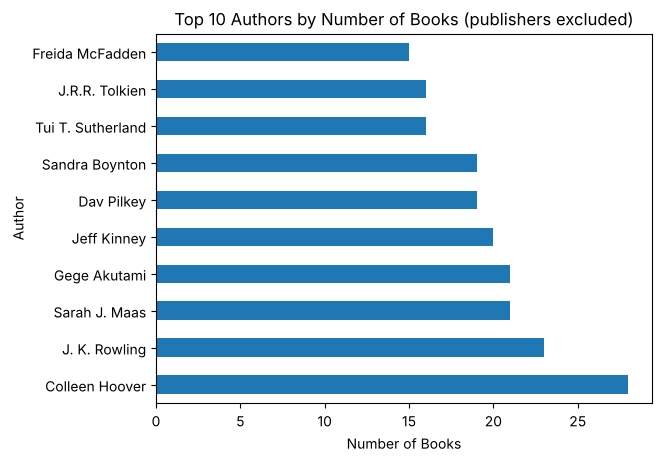

In [36]:
top_authors.plot(kind='barh')

plt.title('Top 10 Authors by Number of Books (publishers excluded)')
plt.xlabel('Number of Books')
plt.ylabel('Author')
plt.show()

In [37]:
df_clean[df_clean['Author'] == 'Calendars Workman'][['Title', 'Author', 'Manufacturer', 'Brand']].head(10)

,Title,Author,Manufacturer,Brand
110,365 Cats Page-A-Day Calendar 2024: The World's...,Calendars Workman,Workman Publishing Company,Workman Publishing
271,365 New Words-A-Year Page-A-Day Calendar 2024:...,Calendars Workman,Workman Publishing Company,Workman Publishing
484,365 Dogs Page-A-Day Calendar 2024: The World's...,Calendars Workman,Workman Publishing Company,Unknown
501,Audubon Engagement Calendar 2024: A Tribute to...,Calendars Workman,Workman Publishing Company,Unknown
516,Today Is Going to Be a Great Day! Page-A-Day C...,Calendars Workman,Workman Publishing Company,Hachette/FaithWords Books
580,Cat Page-A-Day Gallery Calendar 2024: A Deligh...,Calendars Workman,Workman Publishing Company,Workman Publishing
593,Original Sudoku Page-A-Day Calendar 2024: 366 ...,Calendars Workman,Workman Publishing Company,Unknown
636,The New York Times Daily Crossword Page-A-Day ...,Calendars Workman,Workman Publishing Company,Unknown
727,365 Bible Verses-A-Year for 2024 Page-A-Day Ca...,Calendars Workman,Workman Publishing Company,Hachette/FaithWords Books
737,365 Days of Amazing Trivia! Page-A-Day Calenda...,Calendars Workman,Workman Publishing Company,Workman Publishing


In [38]:
df_clean[df_clean['Author'] == 'Ltd. Publications'][['Title', 'Author', 'Manufacturer', 'Brand']].head(10)

,Title,Author,Manufacturer,Brand
219,The Book of Unusual Knowledge,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
533,Crochet Techniques & Tips,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
699,Large Print Merriam-Webster Puzzles 10 Booklet...,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
755,Brain Games - Criminal Mind Puzzles: Collect T...,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
855,Paper Airplane Kit,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
978,Brain Games - Sticker by Number: Ocean Treasures,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
1448,Brain Games - Color by Number: Stress-Free Col...,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
1718,Brain Games - Sticker by Number: Animals - 2 B...,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
1774,Brain Games - Sticker by Number: Animals (28 I...,Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."
1966,Brain Games - Large Print Word Search (Swirls),Ltd. Publications,"Publications International, Ltd.","Publications International, Ltd."


In [39]:
author_counts = df_clean['Author'].value_counts()

author_counts[author_counts >= 5].head(20)

Author
Calendars Workman          40
Ltd. Publications          32
Colleen Hoover             28
J. K. Rowling              23
Sarah J. Maas              21
Gege Akutami               21
Jeff Kinney                20
Publishing Workman         20
Dav Pilkey                 19
Sandra Boynton             19
Sourcebooks Sourcebooks    17
Kitchen America's          17
International Trends       17
Zondervan Zondervan        17
Tui T. Sutherland          16
Publications Editors       16
J.R.R. Tolkien             16
Freida McFadden            15
Rick Riordan               15
DK DK                      15
Name: count, dtype: int64

In [40]:
df_clean['Author'].nunique()

2803

In [41]:
df_clean['Author'].value_counts().head(30)

Author
Calendars Workman          40
Ltd. Publications          32
Colleen Hoover             28
J. K. Rowling              23
Sarah J. Maas              21
Gege Akutami               21
Jeff Kinney                20
Publishing Workman         20
Dav Pilkey                 19
Sandra Boynton             19
Sourcebooks Sourcebooks    17
Kitchen America's          17
International Trends       17
Zondervan Zondervan        17
Tui T. Sutherland          16
Publications Editors       16
J.R.R. Tolkien             16
Freida McFadden            15
Rick Riordan               15
DK DK                      15
Licenses Penguin           14
Dr. Seuss                  14
Kentaro Miura              14
Tatsuki Fujimoto           13
Nelson Thomas              13
Dragons Dungeons           13
Brandon Sanderson          13
Stephen King               12
Mo Willems                 12
Gifts Christian            12
Name: count, dtype: int64

In [42]:
author_stats = people.groupby('Author').agg(
    Listings=('Rank', 'count'),
    Total_Reviews=('Review Count', 'sum'),
    Average_Rating=('Reviews', 'mean'),
    Median_Rank=('Rank', 'median')
)

author_stats = author_stats[author_stats['Listings'] >= 5]

author_stats.sort_values('Total_Reviews', ascending=False).head(8).round(2)

,Listings,Total_Reviews,Average_Rating,Median_Rank
Author,,,,
Colleen Hoover,28,1952358,4.49,1299.0
Sarah J. Maas,21,1480708,4.71,133.0
J. K. Rowling,23,918130,4.84,2252.0
Freida McFadden,15,889306,4.30,1534.0
Kristin Hannah,7,755465,4.60,1000.0
Taylor Jenkins Reid,7,466468,4.33,2233.0
Jeff Kinney,20,432108,4.74,1956.5
Suzanne Collins,6,396002,4.68,382.5


In [43]:
print(f"Distinct authors: {df_clean['Author'].nunique():,}")
print(f"Authors with a single listing: {(df_clean['Author'].value_counts() == 1).mean() * 100:.0f}%")
print(f"Share of all listings by the top 10 authors: {people['Author'].isin(top_authors.index).sum() / len(df_clean) * 100:.1f}%")

Distinct authors: 2,803
Authors with a single listing: 75%
Share of all listings by the top 10 authors: 4.2%


### Author Analysis - Key Findings

- After cleaning author names, removing duplicate editions and excluding publisher names, **Colleen Hoover** has the most listings (28), followed by **J. K. Rowling** (23) and **Sarah J. Maas** (21). Before cleaning, Maas showed 36 listings because several editions were counted separately.
- Hoover also has the most reviews overall (about 1.95 million). Sarah J. Maas stands out on rank: her 21 listings have a median rank of 133, versus 1,299 for Hoover and 2,252 for Rowling.
- Freida McFadden has almost 890,000 reviews but the lowest average rating in this group (4.30): popular does not mean highest rated.
- The list is not dominated by a few names: there are 2,803 distinct authors, 75% appear only once, and the top 10 authors account for only 4.2% of all listings.

## 7. Rating Analysis

In this dataset, Reviews is the product's average customer rating, while Review Count is the number of ratings/reviews. The column names can be easy to confuse, so the distinction is stated here.

### Distribution of Book Ratings

In [44]:
df_clean['Reviews'].value_counts().sort_index()

Reviews
1.0       1
2.1       1
2.5       1
2.6       1
3.0       1
3.1       1
3.3       1
3.4       1
3.5       5
3.6       4
3.7       7
3.8       9
3.9      12
4.0      26
4.1      56
4.2      76
4.3     185
4.4     292
4.5     386
4.6     665
4.7    1031
4.8    1265
4.9     590
5.0      84
Name: count, dtype: int64

In [45]:
df_clean['Reviews'].mean()

np.float64(4.6623271644330995)

In [46]:
df_clean['Reviews'].median()

np.float64(4.7)

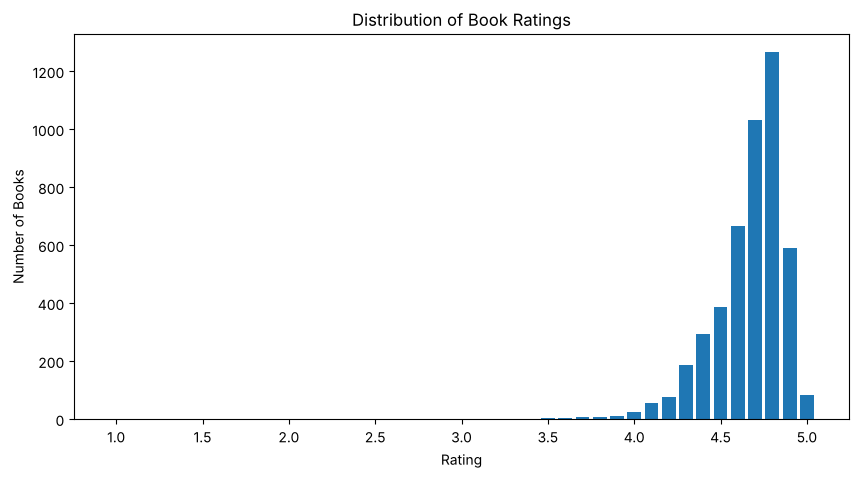

In [47]:
rating_counts = df_clean['Reviews'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(rating_counts.index, rating_counts.values, width=0.08)

plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Books')

plt.xticks(np.arange(1, 5.1, 0.5))

plt.show()

## 8. Review Count Analysis

Most Reviewed Books

In [48]:
top_reviewed = df_clean.sort_values('Review Count',ascending=False).head(10)
top_reviewed[['Title', 'Author', 'Reviews', 'Review Count']]

,Title,Author,Reviews,Review Count
433,Where the Crawdads Sing: Reese's Book Club (A ...,Delia Owens,4.7,621499
58,Verity,Colleen Hoover,4.6,319253
115,It Ends with Us: A Novel (1),Colleen Hoover,4.7,304540
117,The Nightingale: A Novel,Kristin Hannah,4.7,294097
66,The Silent Patient,Alex Michaelides,4.4,284041
148,Reminders of Him: A Novel,Colleen Hoover,4.7,251651
14,Lessons in Chemistry: A Novel,Bonnie Garmus,4.6,250836
145,The Midnight Library: A GMA Book Club Pick (A ...,Matt Haig,4.3,239850
1311,Eleanor Oliphant Is Completely Fine: Reese's B...,Gail Honeyman,4.5,229641
2082,Beneath a Scarlet Sky: A Novel,Mark Sullivan,4.6,224438


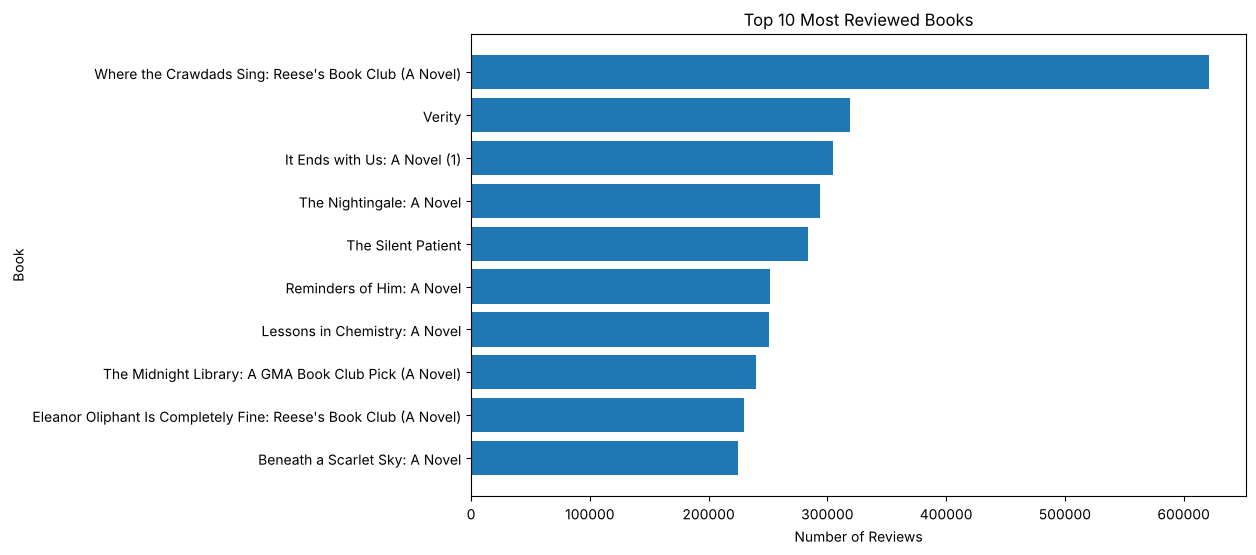

In [49]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_reviewed['Title'],
    top_reviewed['Review Count']
)

plt.title('Top 10 Most Reviewed Books')
plt.xlabel('Number of Reviews')
plt.ylabel('Book')

plt.gca().invert_yaxis()

plt.show()

### Distribution of Review Counts

In [50]:
df_clean['Review Count'].describe()

count      4701.000000
mean      11502.438417
std       25127.961012
min           1.000000
25%         888.000000
50%        3831.000000
75%       11173.000000
max      621499.000000
Name: Review Count, dtype: float64

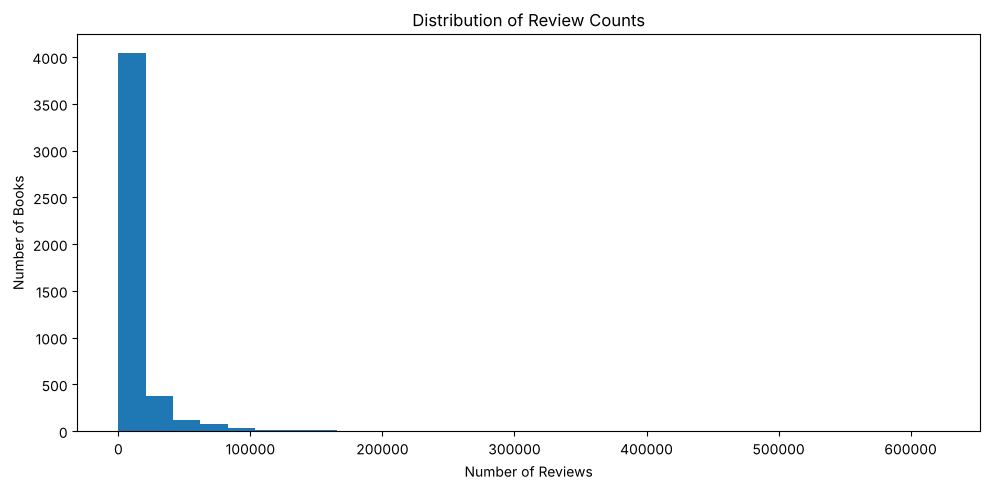

In [51]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean['Review Count'], bins=30)

plt.title('Distribution of Review Counts')
plt.xlabel('Number of Reviews')
plt.ylabel('Number of Books')

plt.tight_layout()
plt.show()

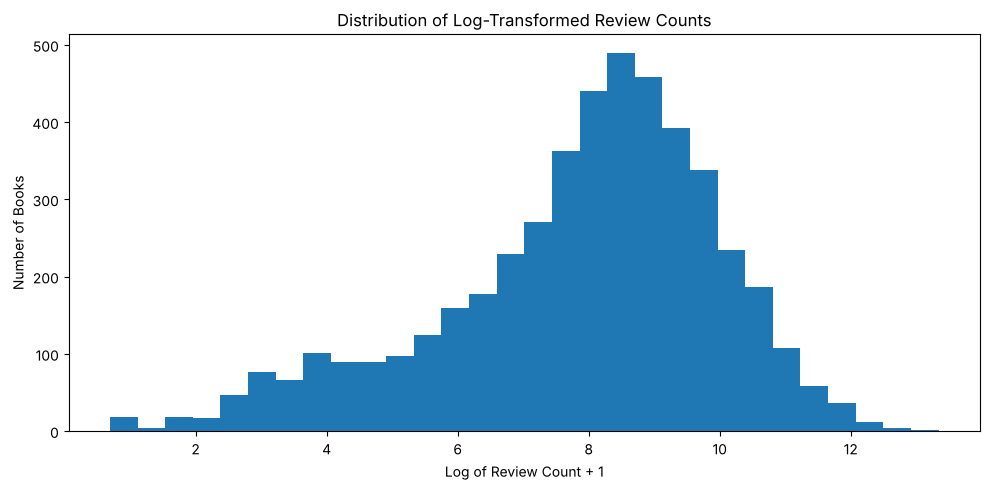

In [52]:
plt.figure(figsize=(10, 5))

plt.hist(
    np.log1p(df_clean['Review Count']),
    bins=30
)

plt.title('Distribution of Log-Transformed Review Counts')
plt.xlabel('Log of Review Count + 1')
plt.ylabel('Number of Books')

plt.tight_layout()
plt.show()

### Rating vs Popularity Analysis

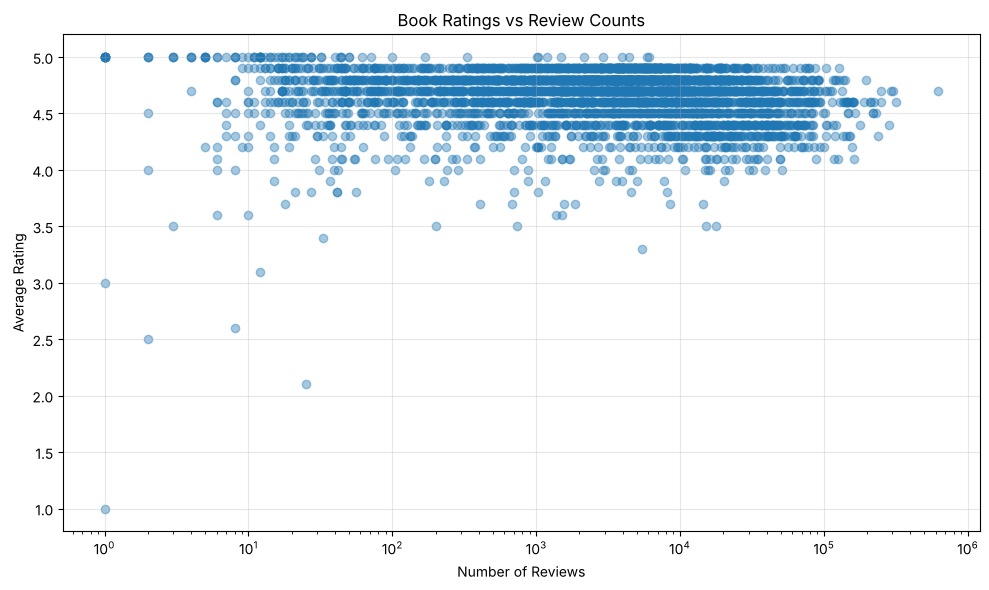

In [53]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_clean['Review Count'],
    df_clean['Reviews'],
    alpha=0.4
)

plt.xscale('log')

plt.title('Book Ratings vs Review Counts')
plt.xlabel('Number of Reviews')
plt.ylabel('Average Rating')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
df_clean['Review Count'].corr(df_clean['Reviews'])

np.float64(-0.1343882898493073)

In [55]:
df_clean['Review Count'].corr(
    df_clean['Reviews'],
    method='spearman'
)

np.float64(-0.18190075426322905)

## 9. Price Analysis

In [56]:
df_clean['Price'].describe()

count    4701.000000
mean       12.965567
std         9.897021
min         0.150000
25%         7.400000
50%        11.000000
75%        15.390000
max       199.990000
Name: Price, dtype: float64

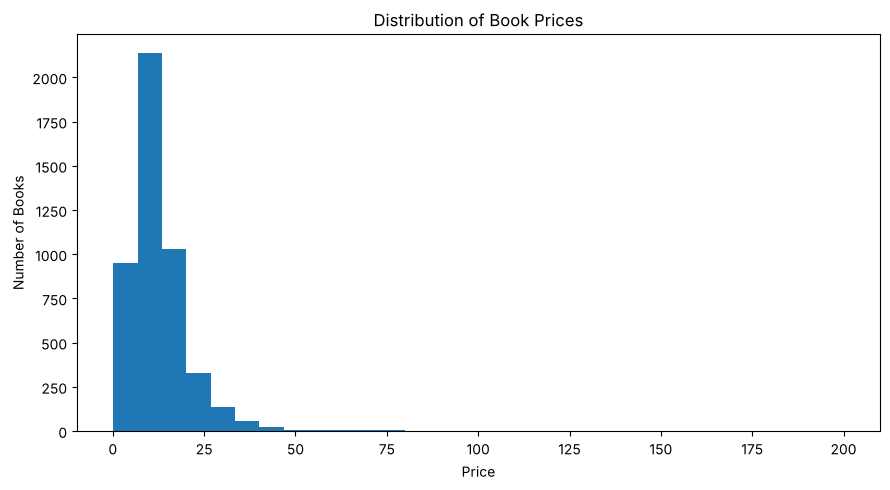

In [57]:
plt.figure(figsize=(9, 5))

plt.hist(df_clean['Price'], bins=30)

plt.title('Distribution of Book Prices')
plt.xlabel('Price')
plt.ylabel('Number of Books')

plt.tight_layout()
plt.show()

In [58]:
df_clean.nsmallest(5,'Price')[['Title','Price']]

,Title,Price
4006,cahier séyès: cahier grands Carreaux 196 pages...,0.15
4123,The Bad Guys (The Bad Guys #1) (1),0.79
2427,Bright Baby Touch & Feel Baby Animals (Bright ...,0.93
1631,A Long Walk to Water: Based on a True Story,0.96
769,Heartstopper #2: A Graphic Novel (2),0.99


In [59]:
df_clean.nlargest(5,'Price')[['Title','Price']]

,Title,Price
2597,"MCAT Complete 7-Book Subject Review 2024-2025,...",199.99
1542,Diagnostic and Statistical Manual of Mental Di...,143.63
513,Throne of Glass Box Set,143.00
3969,One Piece Box Set: East Blue and Baroque Works...,136.18
3608,Akira 35th Anniversary Box Set,127.99


In [60]:
df_clean['Price'].corr(df_clean['Review Count'])

np.float64(-0.13812891490250243)

In [61]:
df_clean['Price'].corr(
    df_clean['Review Count'],
    method='spearman'
)

np.float64(-0.3370503370857858)

### Price vs Popularity

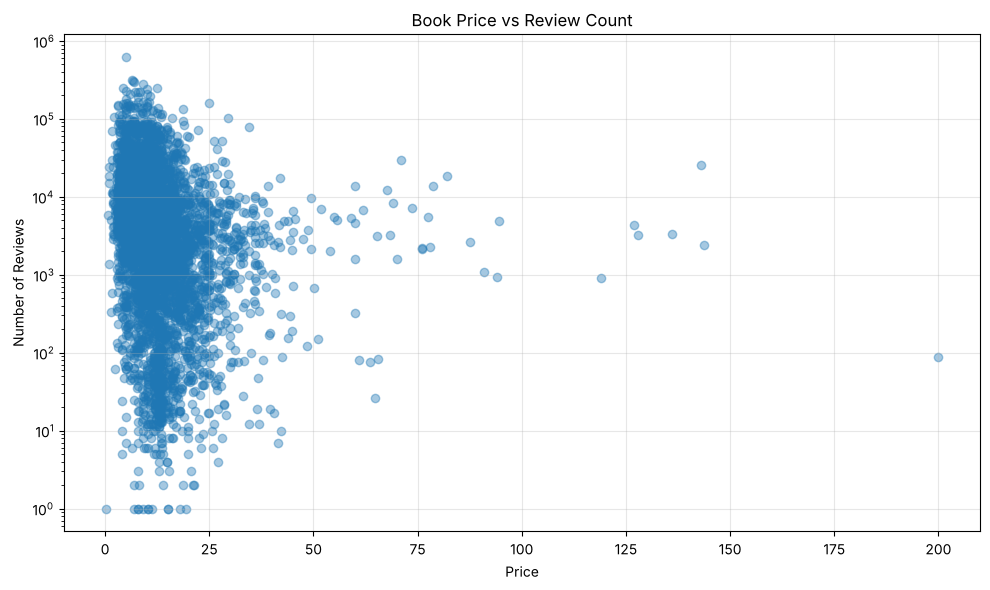

In [62]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_clean['Price'],
    df_clean['Review Count'],
    alpha=0.4
)

plt.yscale('log')

plt.title('Book Price vs Review Count')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Price Analysis - Key Findings

- Most products are concentrated in the lower price range (median \$11.00).
- A few products have exceptionally high prices (boxed sets, textbooks and reference books).
- The Pearson correlation between price and review count is only about -0.14, which suggests a very weak relationship.
- The Spearman (rank-based) correlation is about **-0.34**, a moderate negative relationship: cheaper listings tend to have more reviews. Pearson understates it because review counts are extremely skewed.
- This is an association only; it does not show that price affects review activity.

## 10. Genre Analysis

In [63]:
genre_counts = df_clean['Genre'].value_counts()

genre_counts.head(10)

Genre
Fantasy                    160
Classics                   100
Motivational                96
Genre Fiction               96
Animals                     94
Bibles                      91
Happiness                   77
Contemporary                71
Children's Books            69
Personal Transformation     65
Name: count, dtype: int64

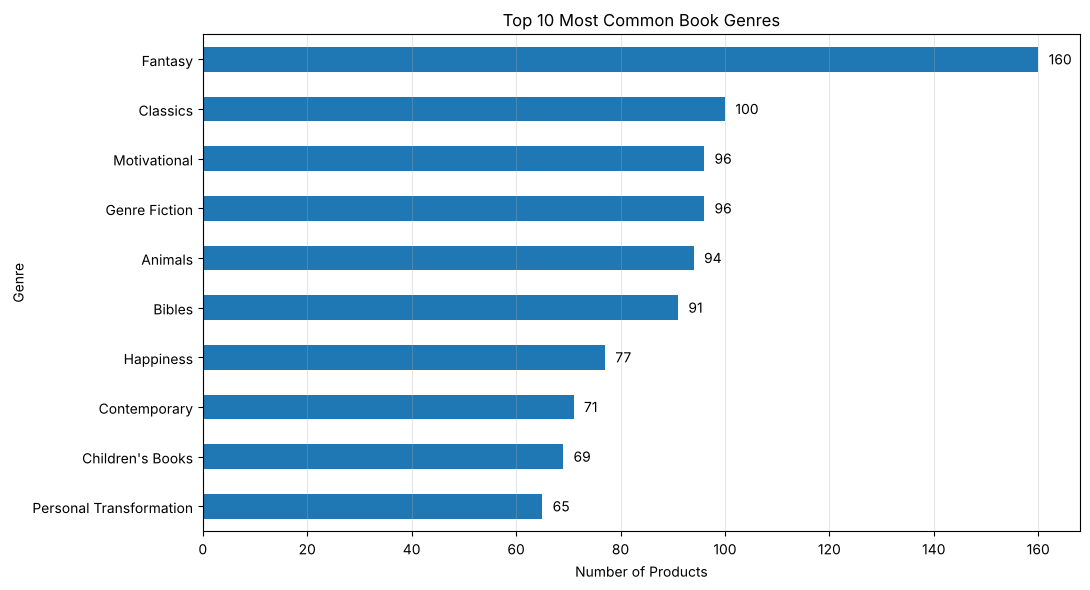

In [64]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(11, 6))

ax = top_genres.plot(kind='barh')

plt.title('Top 10 Most Common Book Genres')
plt.xlabel('Number of Products')
plt.ylabel('Genre')

ax.invert_yaxis()

for i, value in enumerate(top_genres):
    ax.text(value + 2, i, str(value), va = 'center')

plt.grid(axis = 'x', alpha = 0.3)
plt.tight_layout()
plt.show()

### Genre Distribution - Key Findings

The genre comparisons below include only genres with at least 20 products.

- Fantasy is the most frequently occurring genre, with 160 products (3.4% of all listings).
- Classics is second (100 products), followed by Motivational and Genre Fiction (96 each).
- The top 10 genres show a diverse representation of book categories.
- Even the largest category covers only about 3.4% of listings, so the dataset is spread across 900+ genres.

In [65]:
genre_percentage = (
    genre_counts.head(10)/len(df_clean)
)*100

genre_percentage

Genre
Fantasy                    3.403531
Classics                   2.127207
Motivational               2.042119
Genre Fiction              2.042119
Animals                    1.999575
Bibles                     1.935758
Happiness                  1.637949
Contemporary               1.510317
Children's Books           1.467773
Personal Transformation    1.382685
Name: count, dtype: float64

In [66]:
genre_rating = df_clean.groupby('Genre').agg(
    Book_Count = ('Title', 'count'),
    Average_Rating = ('Reviews', 'mean')
)

genre_rating = genre_rating[
    genre_rating['Book_Count'] >= 20
]

genre_rating.sort_values(
    by='Average_Rating',
    ascending=False
).head(10)

,Book_Count,Average_Rating
Genre,,
Bears,20,4.845000
Devotionals,47,4.827660
Bibles,91,4.818681
School,21,4.804762
Women's Issues,29,4.803448
Mystery,25,4.800000
Dinosaurs,20,4.790000
Animals,94,4.787234
Cats,40,4.782500


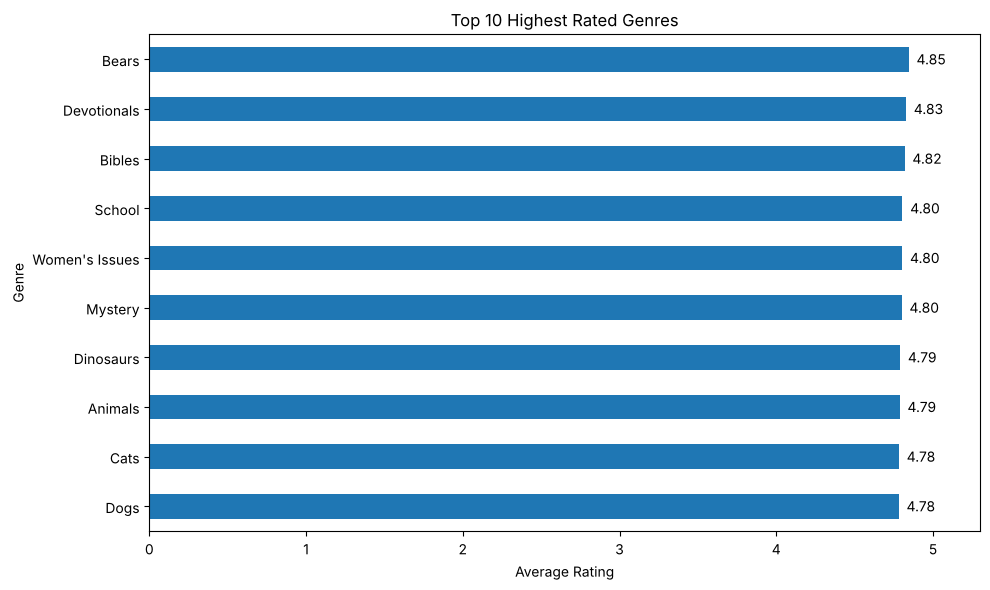

In [67]:
top_rated_genres = genre_rating.sort_values(
    'Average_Rating',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

ax = top_rated_genres['Average_Rating'].plot(
    kind='barh'
)

ax.invert_yaxis()

for i, value in enumerate(top_rated_genres['Average_Rating']):
    ax.text(value + 0.05, i, f'{value:.2f}', va='center')

plt.xlim(0, 5.3)
plt.title('Top 10 Highest Rated Genres')
plt.xlabel('Average Rating')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

The bars now start at zero. The ten highest-rated genres differ by only about 0.06 stars (4.78 to 4.85), so the ranking is a very small difference and should not be over-interpreted.

In [68]:
genre_price = df_clean.groupby('Genre').agg(
    Book_Count=('Title', 'count'),
    Median_Price=('Price', 'median')
)

genre_price = genre_price[
    genre_price['Book_Count'] >= 20
]

In [69]:
top_expensive_genres = genre_price.sort_values(
    by='Median_Price',
    ascending=False
).head(10)

top_expensive_genres

,Book_Count,Median_Price
Genre,,
Bibles,91,18.970
Cooking for One or Two,23,17.500
Quick & Easy,27,17.180
Reference,43,16.740
Performing Arts,59,13.820
Contemporary,71,13.460
Fantasy,160,13.310
Journal Writing,20,13.075
United States,55,12.960


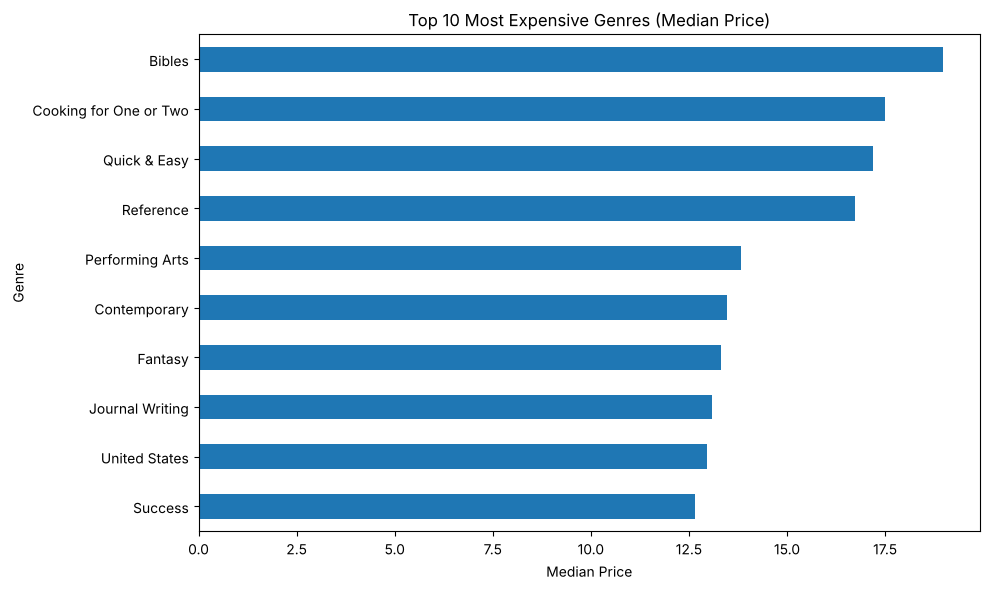

In [70]:
plt.figure(figsize=(10, 6))

ax = top_expensive_genres['Median_Price'].plot(
    kind='barh'
)

ax.invert_yaxis()

plt.title('Top 10 Most Expensive Genres (Median Price)')
plt.xlabel('Median Price')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

In [71]:
genre_price.sort_values(
    by='Median_Price',
    ascending=True
).head(10)

,Book_Count,Median_Price
Genre,,
Bears,20,4.990
Dogs,32,5.340
Dinosaurs,20,5.990
Humor,35,6.430
Coloring Books,34,6.780
Animals,94,7.400
Activity Books,48,7.440
Family Life,58,7.540
School,21,7.970


Genre prices now use the **median** instead of the mean, because a few expensive boxed sets and reference books pull the mean up. Fantasy, for example, looks expensive at about \$20 on average, but its median price is \$13.31. Bibles are the most expensive genre by median (\$18.97), and Bears, Dogs and Dinosaurs are the cheapest (about \$5 to \$6).

## 11. Relationship Analysis

Pearson correlation describes linear association and is sensitive to outliers and skew. Review counts are strongly right-skewed in this dataset, so the Pearson results above understate some relationships. In the matrix below I use the **Spearman** rank correlation instead, which is not affected by skew or outliers, and I added `Rank`. Correlation does not establish causation.

### 11.1 Rating vs Price

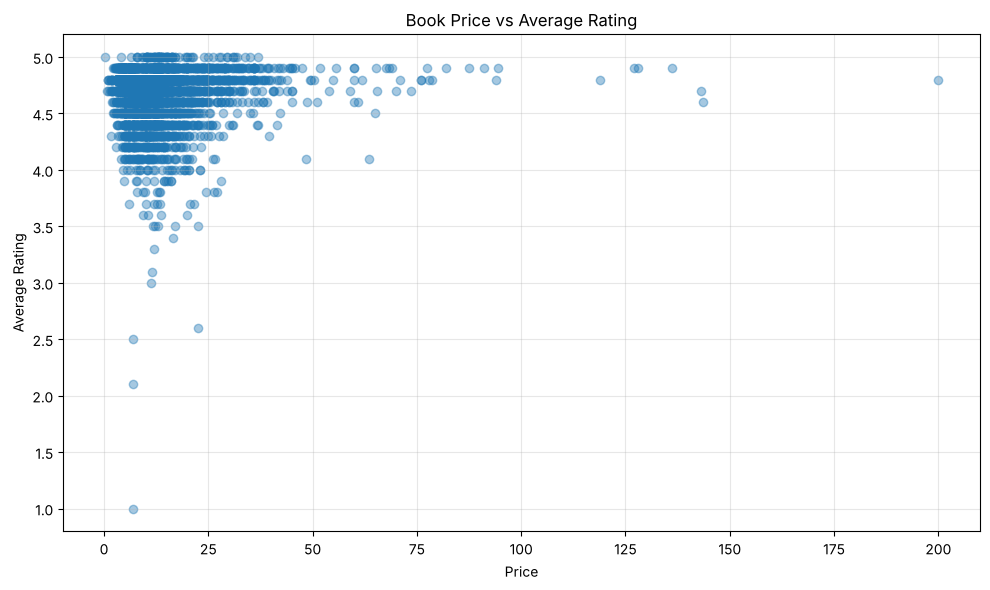

In [72]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_clean['Price'],
    df_clean['Reviews'],
    alpha=0.4
)

plt.title('Book Price vs Average Rating')
plt.xlabel('Price')
plt.ylabel('Average Rating')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [73]:
df_clean['Price'].corr(df_clean['Reviews'])

np.float64(0.09137491095283065)

In [74]:
correlation = df_clean[
    ['Rank', 'Price', 'Reviews', 'Review Count']
].corr(method='spearman')

correlation

,Rank,Price,Reviews,Review Count
Rank,1.000000,0.014651,0.015629,-0.225119
Price,0.014651,1.000000,0.084043,-0.337050
Reviews,0.015629,0.084043,1.000000,-0.181901
Review Count,-0.225119,-0.337050,-0.181901,1.000000


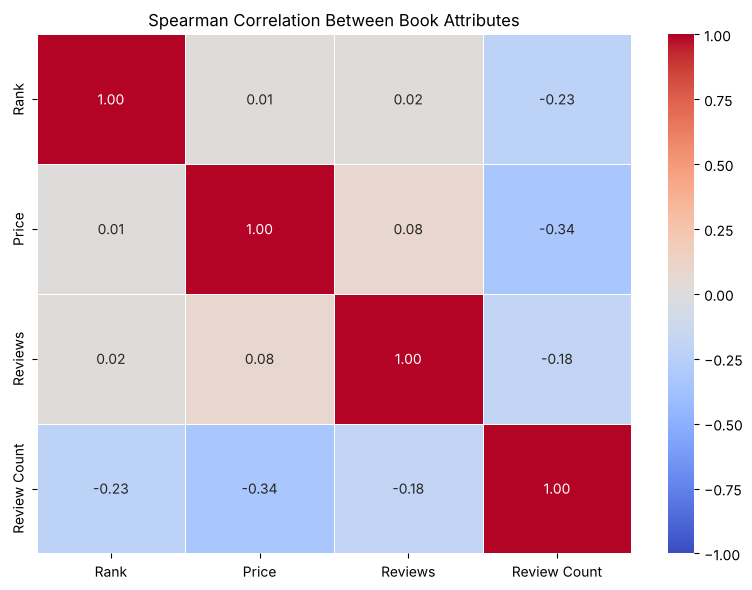

In [75]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Spearman Correlation Between Book Attributes')
plt.tight_layout()
plt.show()

### 11.2 What is associated with a better Rank?

Rank 1 is the best seller, so a *negative* correlation with `Rank` means "higher value goes with a better rank".
The heatmap above already includes `Rank`. To make it concrete, I split all listings into four equal groups by
rank (Q1 = best ranked) and compare the medians.

In [76]:
top100 = df_clean.nsmallest(100, 'Rank')

print(f"Median review count of the 100 best-ranked listings: {top100['Review Count'].median():,.0f}")
print(f"Of those 100, how many have fewer than 100 reviews: {(top100['Review Count'] < 100).sum()}")
print(f"Overall median review count, for comparison: {df_clean['Review Count'].median():,.0f}")

Median review count of the 100 best-ranked listings: 24,287
Of those 100, how many have fewer than 100 reviews: 3
Overall median review count, for comparison: 3,831


In [77]:
df_clean['Rank_Group'] = pd.qcut(
    df_clean['Rank'],
    4,
    labels=['Q1 (best)', 'Q2', 'Q3', 'Q4 (lowest)']
)

rank_groups = df_clean.groupby('Rank_Group', observed=True).agg(
    Listings=('Title', 'count'),
    Median_Reviews=('Review Count', 'median'),
    Median_Rating=('Reviews', 'median'),
    Median_Price=('Price', 'median'),
    Median_Pages=('Number of Pages', 'median')
).round(2)

rank_groups

,Listings,Median_Reviews,Median_Rating,Median_Price,Median_Pages
Rank_Group,,,,,
Q1 (best),1177,8263.0,4.7,10.99,304.0
Q2,1174,3966.0,4.7,10.70,256.0
Q3,1175,3130.0,4.7,11.44,264.0
Q4 (lowest),1175,2588.0,4.7,11.16,272.0


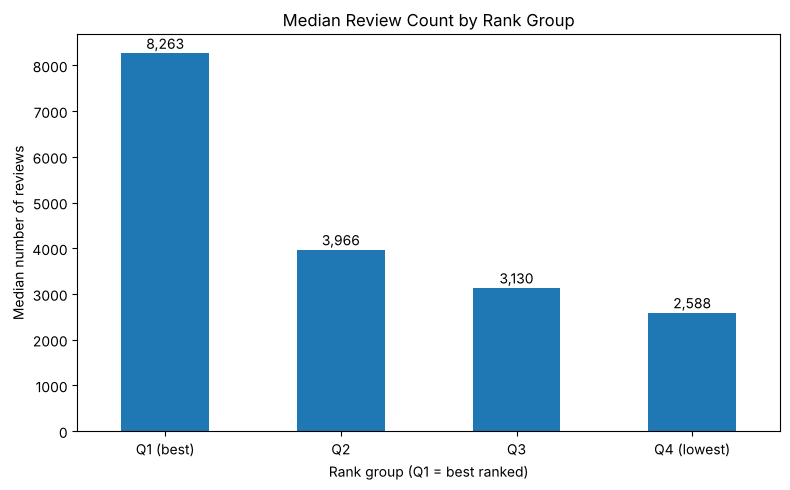

In [78]:
plt.figure(figsize=(8, 5))

ax = rank_groups['Median_Reviews'].plot(kind='bar', rot=0)

for i, value in enumerate(rank_groups['Median_Reviews']):
    ax.text(i, value + 100, f'{value:,.0f}', ha='center')

plt.title('Median Review Count by Rank Group')
plt.xlabel('Rank group (Q1 = best ranked)')
plt.ylabel('Median number of reviews')

plt.tight_layout()
plt.show()

### Rank - Key Findings

- **Review count is the only attribute with a meaningful link to Rank** (Spearman -0.23: more reviews go with a better rank). Price (0.01) and rating (0.02) show essentially no relationship with rank.
- The best-ranked quarter of listings has a median of 8,263 reviews versus 2,588 for the lowest-ranked quarter (about 3.2x), while the median rating (4.7 in every group) and median price (about \$10.70 to \$11.44) barely change.
- Among the 100 best-ranked listings the median review count is 24,287 (3,831 overall), and only 3 have fewer than 100 reviews.
- The link is moderate, not strong. Rank most likely reflects recent sales while reviews accumulate over time, so a new release can rank high with almost no reviews (ranks 4, 9 and 10 have only 6, 1 and 1 reviews).
- As before, this is an association, not proof that reviews cause a better rank.

## 12. Key Findings and Insights

The exploratory data analysis revealed the following findings:

| Area | Key Finding |
|---|---|
| Dataset | 4,846 raw product listings and 10 attributes; 4,701 after removing 145 duplicate listings of the same book (other editions). About 87% are regular books; the rest are puzzle/activity books (247), calendars (219) and box sets (134). |
| Average rating | The mean in the Reviews column is approximately 4.66 out of 5 (median 4.7). |
| Data quality | In the raw data Brand has 1,702 missing values and Number of Pages has 71. Missing brands are labeled Unknown; missing page counts remain missing (69 after duplicates were removed). Author names were standardised (2,901 to 2,805 distinct names). |
| Authors | After excluding publisher names: Colleen Hoover has the most listings (28), then J. K. Rowling (23) and Sarah J. Maas (21). 75% of authors appear only once; the top 10 account for 4.2% of listings. |
| Most reviewed | Where the Crawdads Sing has the most reviews (621,499); Colleen Hoover has 3 of the 10 most reviewed books. |
| Genres | Fantasy is the most frequent genre, with 160 products (3.4%). |
| Highest-rated genre | Bears, average rating 4.85 across 20 products, among genres with at least 20 products (the top 10 genres differ by only about 0.06 stars). |
| Highest-priced genre | Bibles, median price \$18.97 across 91 products, among genres with at least 20 products. |
| Lowest-priced genre | Bears, median price \$4.99 across 20 products, among genres with at least 20 products. |
| Price vs average rating | Spearman correlation: +0.08, a very weak positive association (Pearson +0.09). |
| Price vs review count | Spearman correlation: -0.34, a moderate negative association; cheaper listings tend to have more reviews (Pearson -0.14 understates it). |
| Average rating vs review count | Spearman correlation: -0.18, a weak negative association (Pearson -0.13). |
| Rank vs review count | Spearman correlation: -0.23. The best-ranked quarter of listings has about 3.2x the median review count of the lowest-ranked quarter. |
| Rank vs price and rating | Spearman correlations of 0.01 and 0.02: no meaningful relationship. |

The correlations describe associations in this dataset; they do not show that one attribute causes another. Because review counts are highly skewed, the Spearman (rank-based) correlations are the main results and the Pearson values are shown for comparison. The dataset source, collection date, price currency, and rank definition still need to be confirmed before making broader claims.

## 13. Limitations and Future Scope

### Limitations

1. The dataset is a particular collection of product listings and may not represent all Amazon books or current rankings. Record its source and collection date when known.
2. The raw data contains missing values in Brand (1,702) and Number of Pages (71). Missing brands are labeled Unknown; page counts are not imputed.
3. The Genre column contains 907 unique labels. Genre averages are restricted to categories with at least 20 products, but those groups still have different sample sizes.
4. Author names were standardised and publisher-like names were excluded from the author ranking, but this relied on heuristics and a hand-curated list covering the top of the ranking, so some mistakes remain (for example spellings that differ by a middle name).
5. Duplicate editions were identified with rules (same title and author, or same author with identical rating and review count), which may remove a few distinct books or miss some duplicates.
6. The dataset includes non-book products (about 13%: calendars, boxed sets, puzzle books). They are tagged in the `Type` column but still included, so conclusions apply to product listings.
7. The price currency and the definition of Rank are not documented here and should be verified from the source.
8. Review count and average rating cannot independently establish actual sales performance.
9. Correlations identify association, not causation.

### Future Scope
1. Document the dataset source, collection date, price currency, and rank definition.
2. Repeat the analysis on regular books only, using the `Type` column.
3. Add a publication year to separate new releases from long-term sellers, since rank likely reflects recent sales.
4. Develop an interactive dashboard using Streamlit.
5. Explore broader genre classification and relationships between product characteristics and ranking.